In [2]:
%matplotlib widget
import numpy as np
import tomllib
from pathlib import Path

from thesis_code.plotting import plot_performance, plot_gradients, plot_weight_matrices, InteractiveSpikePlot

In [3]:
work_dir = Path.cwd()
print(work_dir)
with open(work_dir / "config.toml", 'rb') as cfg_file:
    cfg = tomllib.load(cfg_file)

n_trials = cfg["training"]["n_trials"]
# def get_data(data_group: str, data_name: str) -> np.ndarray:
    # return np.array([np.load(work_dir / f"seed_{i}" / "data_net" / data_group / data_name) for i in range(n_trials)])

c:\Users\emiel\Documents\Study\Thesis\Thesis-Code\outputs\2026-10-13_11-04-09-test_network_no_daleslaw


In [4]:
def load_recording(path: Path) -> np.ndarray:
    with np.load(path) as d:
        arr = d["data"]
        if "n_cols" in d.files:
            arr = np.unpackbits(arr, axis=-1, count=int(d["n_cols"])).astype(bool)
    return arr

def get_data(data_group: str, data_name: str) -> np.ndarray:
    # data_name without extension, e.g. "spikes_hidden_0"
    return np.array([
        load_recording(work_dir / f"seed_{i}" / "data_net" / data_group / f"{data_name}.npz")
        for i in range(n_trials)
    ])

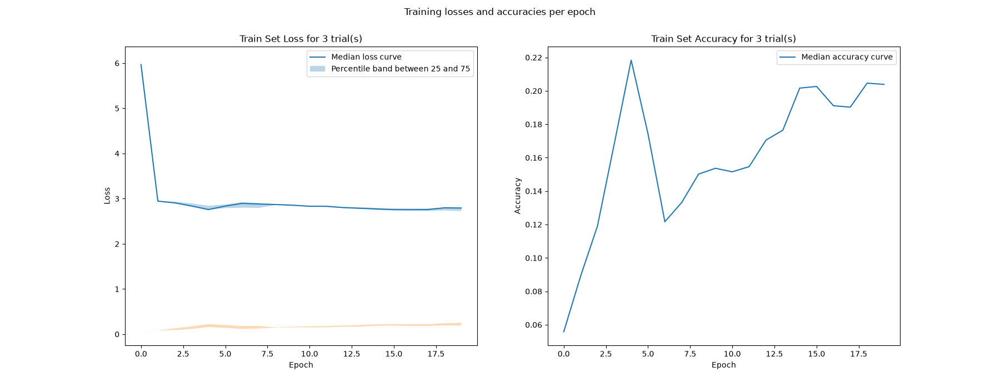

In [5]:
loss_rec = get_data("performance", "loss")
acc_rec = get_data("performance", "acc")
plot_performance(loss_rec, acc_rec)

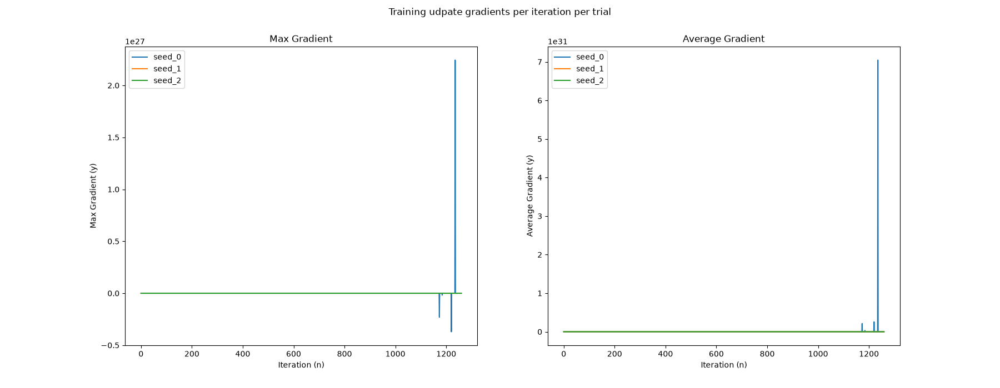

In [6]:
max_grad_rec = get_data("gradients", "avg_grad")
avg_grad_rec = get_data("gradients", "max_grad")
plot_gradients(max_grad_rec, avg_grad_rec)










In [7]:
weights_forward_0 = get_data("weights", "weights_forward_0")
plot_weight_matrices(weights_forward_0, name="weights_forward_0")

weights_forward_1 = get_data("weights", "weights_forward_1")
plot_weight_matrices(weights_forward_1, name="weights_forward_1")

weights_recurrent_0 = get_data("weights", "weights_recurrent_0")
plot_weight_matrices(weights_recurrent_0, name="weights_recurrent_0")

In [ ]:
layer_spikes = {
    "spikes_in": get_data("spikes", "spikes_in")[0],
    "spikes_hidden_0": get_data("spikes", "spikes_hidden_0")[0],
    "spikes_out": get_data("spikes", "spikes_out")[0],
    "targets": get_data("spikes", "targets")[0],
}
isp = InteractiveSpikePlot(layer_spikes, range(1, 21))
isp.draw()
# isp.save_as_pdf()

ValueError: setting an array element with a sequence. The requested array has an inhomogeneous shape after 2 dimensions. The detected shape was (3, 20) + inhomogeneous part.